# 6 – RAG with Microsoft GraphRAG

Notebook 5 answered broad questions with a tree of summaries built from *embedding clusters*. **GraphRAG** (Edge et al., 2024, [*From Local to Global: A Graph RAG Approach to Query-Focused Summarization*](https://arxiv.org/abs/2404.16130); open source at [github.com/microsoft/graphrag](https://github.com/microsoft/graphrag)) builds its hierarchy from something more explicit: a **knowledge graph** of the entities in the documents and the relationships between them.

**Indexing** turns the documents into that graph and summarises it:

```
documents ─► text units (chunks)
                 │  LLM: extract entities and relationships, plus one "gleaning" pass for what was missed
                 ▼
             entity and relationship descriptions ─ LLM: merge duplicates ─► knowledge graph
                                                                                │  Leiden community detection
                                                                                ▼
                                                     hierarchy of communities (level 0 = coarsest)
                                                                                │  LLM: one report per community
                                                                                ▼
                                                                       community reports
                                                                                │  embedding model
                                                                                ▼
                        vectors of entity descriptions, text units and reports (LanceDB)
```

**Querying** offers four methods:

| Method | What it reads | Good for |
|---|---|---|
| **global** | all community reports of one level, map–reduce style | questions about the whole corpus: themes, comparisons, "what is this about?" |
| **local** | the entities closest to the question, their relationships, their text units and community reports | questions about specific entities |
| **DRIFT** | a global "primer", then local follow-up searches | broad questions that need detail |
| **basic** | text units by vector similarity | the plain vector RAG of Example 1, for comparison |

The paper's central claim is about the first row. For *global sensemaking* questions, which no single chunk can answer, a map–reduce over community summaries gives more comprehensive and more diverse answers than vector RAG.

This notebook indexes our four documents with GraphRAG 3.3. It then looks at every table GraphRAG produces, draws the knowledge graph and its community hierarchy (static and interactive), reads a community report, and compares the search methods.

Unlike the other notebooks, this one uses **OpenAI's API** (`gpt-4.1-mini` and `text-embedding-3-small`) instead of Ollama. Indexing makes dozens of long LLM calls. With the API it takes under two minutes and costs a few cents. With `mistral-small3.2:24b` on a laptop, a test run needed 14 minutes for the extraction alone and about a minute per community report – roughly 45 minutes for this index. *Things to try* shows the settings for running it locally anyway.

**Before you run it**

- GraphRAG supports Python 3.11–3.13, which is why the whole project runs on Python 3.13; `requirements.txt` installs GraphRAG together with everything else.
- Put your OpenAI key into `.env` in the project folder: `OPENAI_API_KEY=sk-...`.
- The index is stored in `graphrag_workspace/output` and every model response in `graphrag_workspace/cache`, so later runs skip the work.

## Imports

- `graphrag.api` – GraphRAG's Python API: `build_index` runs the indexing pipeline; `global_search`, `local_search`, `drift_search` and `basic_search` answer questions. All of them are `async` functions, so we call them with `await`, which Jupyter allows directly in a cell.
- `load_config` – reads `settings.yaml` into a validated `GraphRagConfig`.
- `load_dotenv` – loads the OpenAI key from the project's `.env` into the environment (python-dotenv comes with GraphRAG).
- `GRAPH_EXTRACTION_PROMPT` – GraphRAG's default entity-extraction prompt, which we print.
- `yaml` – to write `settings.yaml` (PyYAML comes with GraphRAG).
- `pandas` – GraphRAG stores every output as a Parquet table.
- `networkx`, `numpy`, `matplotlib` – to build and draw the graph; `pyvis` – for an interactive view; `HTML`, `Markdown` and `display` from IPython – to show HTML and formatted answers in the notebook; `escape` – to embed the interactive page safely; `shorten` – to fit long community titles into legends.

In [1]:
import json
import os
import shutil
import time
from html import escape
from pathlib import Path
from textwrap import shorten

import graphrag.api as api
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import yaml
from dotenv import load_dotenv
from graphrag.config.load_config import load_config
from graphrag.prompts.index.extract_graph import GRAPH_EXTRACTION_PROMPT
from IPython.display import HTML, Markdown, display
from pyvis.network import Network

## Configuration

- `PROJECT_DIR`, `DATA_DIR`, `WORKSPACE` – absolute paths. GraphRAG works inside a *project folder* (here `graphrag_workspace/`) that holds its settings, input, output, cache and logs.
- `LLM_MODEL = "gpt-4.1-mini"` – fast, inexpensive, and reliable at GraphRAG's strict output formats. The GPT-5 models reason before they answer, which makes them slower here, and they do not accept a temperature setting.
- `EMBEDDING_MODEL = "text-embedding-3-small"` with `EMBEDDING_DIMENSIONS = 1536`, the size of its vectors. GraphRAG's vector store has to be told the size; its default, 3,072, is that of `text-embedding-3-large`.
- `ENTITY_TYPES` – which kinds of entities the LLM should extract. GraphRAG's defaults are organization, person, geo and event. Our documents are full of assets (wind farms, trams, vehicles) and financial instruments (loans, leases, credit lines), so we add those two types. GraphRAG's *prompt tuning* (see *Things to try*) can propose types automatically.
- `DOCUMENTS` – the four source files and the names under which GraphRAG gets them. GraphRAG uses the file name as the document title, and we will ask it to put that title in front of every chunk. Naming every file after its document therefore tells the LLM in every chunk which company "the Company" is (the problem of Examples 2 and 4).
- `COMMUNITY_LEVEL = 2`, `RESPONSE_TYPE` – query settings: the deepest community level the searches may use (GraphRAG's CLI default), and the desired answer format.
- `SEED` – for the graph layouts.

In [2]:
PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
WORKSPACE = PROJECT_DIR / "graphrag_workspace"

LLM_MODEL = "gpt-4.1-mini"
EMBEDDING_MODEL = "text-embedding-3-small"
EMBEDDING_DIMENSIONS = 1536

ENTITY_TYPES = ["organization", "person", "geo", "event", "asset", "financial_instrument"]
DOCUMENTS = {
    "document_a.md": "The Employer Group, Inc. - Financial Statements 2019 and 2018.md",
    "novaterra_annual_report.txt": "Novaterra Energy AG - Annual Report 2025.txt",
    "meridian_credit_policy.txt": "Meridian Bank - Retail Credit Policy 7.2.txt",
    "harbor_city_transit.txt": "Harbor City Transit Authority - Annual Service Review 2025.txt",
}

COMMUNITY_LEVEL = 2
RESPONSE_TYPE = "multiple paragraphs"
SEED = 7

plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 10})

## Step 1 – The project folder

A GraphRAG project needs an `input/` folder with the documents and a `settings.yaml`. (The command `graphrag init` would create a template; we write ours directly so that every setting is visible here.) Secrets do not go into the settings: they refer to environment variables, which we load from the project's `.env` in step 2.

**Input.** The four documents are copied into `input/` under the names from `DOCUMENTS`. The financial statements get the same clean-up as in notebook 5: escaped dollar signs are restored and the `---` rules removed. The folder is rebuilt on every run.

**Settings.** The configuration is a nested dictionary, written out as YAML:

- `completion_models` / `embedding_models` – GraphRAG 3 talks to models through [LiteLLM](https://docs.litellm.ai/), so any LiteLLM provider works; ours is `openai`. `api_key: ${OPENAI_API_KEY}` is a reference that GraphRAG fills in from the environment when it loads the settings, so the key itself never appears in this file. `temperature: 0` makes the extraction as repeatable as possible, and `exponential_backoff` retries a call after a rate-limit error. GraphRAG sends up to 25 calls in parallel (`concurrent_requests`, left at its default), which is why indexing is fast with an API.
- `input` – plain text files. The default pattern only matches `.txt`; ours also takes `.md`. The pattern ends in `$$` because GraphRAG substitutes `${...}` environment variables in the settings file with Python's `string.Template`, in which a literal `$` must be written `$$`.
- `chunking` – GraphRAG's default of 1,200-token chunks with 100 tokens of overlap, counted with the `o200k_base` tokenizer. `prepend_metadata: [title]` puts the document title (the file name) at the start of every chunk.
- `input_storage`, `output_storage`, `reporting`, `cache` – where GraphRAG reads and writes. The `json` cache stores every LLM response, keyed by the exact request, so an interrupted or repeated run only calls the LLM for requests it has not seen.
- `vector_store` – LanceDB, an embedded vector database stored in `output/lancedb`, sized for 1,536-dimensional vectors.
- `extract_graph` – our entity types, and `max_gleanings: 1`: after the first extraction the LLM is asked once more for entities it missed (the paper's *gleaning*).
- `summarize_descriptions` – when an entity is described in several chunks, an LLM merges the descriptions into one of at most 500 tokens.
- `cluster_graph` – Leiden community detection: communities larger than `max_cluster_size: 10` entities are split further into sub-communities. `use_lcc: false` is essential for a corpus like ours: by default GraphRAG clusters only the *largest connected component* of the graph. Our four documents are about unrelated organisations, so their sub-graphs are not connected. The default would silently leave three of them without communities, and that hides them from both global search (which reads only community reports) and local search (which only considers entities that belong to a community).
- `community_reports` – one LLM report per community, at most 2,000 tokens long, from at most 8,000 tokens of input.
- `snapshots.graphml: true` – also writes the graph as `output/graph.graphml`, which graph tools such as Gephi can open.
- the four `*_search` sections – which models each search method uses.

In [3]:
input_dir = WORKSPACE / "input"
if input_dir.exists():
    shutil.rmtree(input_dir)
input_dir.mkdir(parents=True)
for source, title in DOCUMENTS.items():
    text = (DATA_DIR / source).read_text(encoding="utf-8").replace("\\$", "$")
    text = "\n".join(line for line in text.splitlines() if line.strip() != "---")
    (input_dir / title).write_text(text, encoding="utf-8")


settings = {
    "completion_models": {
        "default_completion_model": {
            "model_provider": "openai", "model": LLM_MODEL, "api_key": "${OPENAI_API_KEY}",
            "call_args": {"temperature": 0}, "retry": {"type": "exponential_backoff"},
        },
    },
    "embedding_models": {
        "default_embedding_model": {
            "model_provider": "openai", "model": EMBEDDING_MODEL, "api_key": "${OPENAI_API_KEY}",
            "retry": {"type": "exponential_backoff"},
        },
    },
    "input": {"type": "text", "file_pattern": r".*\.(txt|md)$$"},
    "chunking": {"type": "tokens", "size": 1200, "overlap": 100, "encoding_model": "o200k_base",
                 "prepend_metadata": ["title"]},
    "input_storage": {"type": "file", "base_dir": "input"},
    "output_storage": {"type": "file", "base_dir": "output"},
    "reporting": {"type": "file", "base_dir": "logs"},
    "cache": {"type": "json", "storage": {"type": "file", "base_dir": "cache"}},
    "vector_store": {"type": "lancedb", "db_uri": "output/lancedb", "vector_size": EMBEDDING_DIMENSIONS},
    "embed_text": {"embedding_model_id": "default_embedding_model"},
    "extract_graph": {"completion_model_id": "default_completion_model", "entity_types": ENTITY_TYPES,
                      "max_gleanings": 1},
    "summarize_descriptions": {"completion_model_id": "default_completion_model", "max_length": 500},
    "cluster_graph": {"max_cluster_size": 10, "use_lcc": False},
    "community_reports": {"completion_model_id": "default_completion_model", "max_length": 2000,
                          "max_input_length": 8000},
    "snapshots": {"graphml": True},
    "local_search": {"completion_model_id": "default_completion_model",
                     "embedding_model_id": "default_embedding_model"},
    "global_search": {"completion_model_id": "default_completion_model"},
    "drift_search": {"completion_model_id": "default_completion_model",
                     "embedding_model_id": "default_embedding_model"},
    "basic_search": {"completion_model_id": "default_completion_model",
                     "embedding_model_id": "default_embedding_model"},
}
(WORKSPACE / "settings.yaml").write_text(yaml.safe_dump(settings, sort_keys=False), encoding="utf-8")

print("input:", *sorted(p.name for p in input_dir.iterdir()), sep="\n  ")
print("\nsettings.yaml:\n")
print((WORKSPACE / "settings.yaml").read_text())

input:
  Harbor City Transit Authority - Annual Service Review 2025.txt
  Meridian Bank - Retail Credit Policy 7.2.txt
  Novaterra Energy AG - Annual Report 2025.txt
  The Employer Group, Inc. - Financial Statements 2019 and 2018.md

settings.yaml:

completion_models:
  default_completion_model:
    model_provider: openai
    model: gpt-4.1-mini
    api_key: ${OPENAI_API_KEY}
    call_args:
      temperature: 0
    retry:
      type: exponential_backoff
embedding_models:
  default_embedding_model:
    model_provider: openai
    model: text-embedding-3-small
    api_key: ${OPENAI_API_KEY}
    retry:
      type: exponential_backoff
input:
  type: text
  file_pattern: .*\.(txt|md)$$
chunking:
  type: tokens
  size: 1200
  overlap: 100
  encoding_model: o200k_base
  prepend_metadata:
  - title
input_storage:
  type: file
  base_dir: input
output_storage:
  type: file
  base_dir: output
reporting:
  type: file
  base_dir: logs
cache:
  type: json
  storage:
    type: file
    base_dir: cach

## Step 2 – Loading the configuration, and the extraction prompt

`load_dotenv(PROJECT_DIR / ".env")` puts `OPENAI_API_KEY` into the environment of the Python process. `load_config(WORKSPACE)` then reads `settings.yaml`, substitutes `${OPENAI_API_KEY}` and validates everything into a `GraphRagConfig` object. Two details:

- `load_config` makes the project folder the working directory of the Python process, and resolves most relative paths there. We change back afterwards, so that the rest of the notebook behaves normally.
- The cache path is the one setting it leaves relative, so we pass it as an absolute path through `cli_overrides` – the same mechanism the `graphrag` command uses for its command-line options.

In [4]:
load_dotenv(PROJECT_DIR / ".env")
config = load_config(WORKSPACE, cli_overrides={"cache": {"storage": {"base_dir": str(WORKSPACE / "cache")}}})
os.chdir(PROJECT_DIR)

completion = config.completion_models["default_completion_model"]
embedding = config.embedding_models["default_embedding_model"]
print(f"completion model: {completion.model_provider}/{completion.model}")
print(f"embedding model:  {embedding.model_provider}/{embedding.model}, {config.vector_store.vector_size} dimensions")
print(f"output:           {config.output_storage.base_dir}")

completion model: openai/gpt-4.1-mini
embedding model:  openai/text-embedding-3-small, 1536 dimensions
output:           /Users/vaheandonians/code/rag/graphrag_workspace/output


The heart of GraphRAG is a single prompt. For every chunk, the LLM is asked to list entities and relationships in a strict line format, with `<|>` between the fields and `##` between the records. Each entity gets a name, a type and a description; each relationship gets a source, a target, a description and a *strength* score. That score becomes the edge weight of the graph. Here is the instruction part; the prompt continues with three worked examples, the entity types and the chunk itself:

In [5]:
print(GRAPH_EXTRACTION_PROMPT.split("-Examples-")[0].strip())

-Goal-
Given a text document that is potentially relevant to this activity and a list of entity types, identify all entities of those types from the text and all relationships among the identified entities.
 
-Steps-
1. Identify all entities. For each identified entity, extract the following information:
- entity_name: Name of the entity, capitalized
- entity_type: One of the following types: [{entity_types}]
- entity_description: Comprehensive description of the entity's attributes and activities
Format each entity as ("entity"<|><entity_name><|><entity_type><|><entity_description>)
 
2. From the entities identified in step 1, identify all pairs of (source_entity, target_entity) that are *clearly related* to each other.
For each pair of related entities, extract the following information:
- source_entity: name of the source entity, as identified in step 1
- target_entity: name of the target entity, as identified in step 1
- relationship_description: explanation as to why you think the

## Step 3 – Indexing

`api.build_index(config=config)` runs the whole pipeline and returns one result per *workflow*. The workflows run in this order:

1. `load_input_documents`, `create_base_text_units`, `create_final_documents` – read the files and cut them into text units (chunks).
2. `extract_graph` – the LLM extraction above for every text unit, plus the gleaning pass. Then entities with the same name are merged, and `summarize_descriptions` combines their descriptions.
3. `finalize_graph` – computes every entity's degree (its number of relationships) and assigns ids.
4. `extract_covariates` – claim extraction, disabled by default.
5. `create_communities` – hierarchical Leiden clustering of the graph.
6. `create_final_text_units` – links every text unit to its entities and relationships.
7. `create_community_reports` – one LLM report per community.
8. `generate_text_embeddings` – embeds entity descriptions, text units and the full community reports into LanceDB.

If the output already exists, the cell skips indexing; delete `graphrag_workspace/output` to rebuild. With the cache in place, a rebuild only calls the LLM for requests that have changed.

In [6]:
if (WORKSPACE / "output" / "community_reports.parquet").exists():
    print("Index found in graphrag_workspace/output - skipping indexing.")
else:
    start = time.time()
    results = await api.build_index(config=config)
    for result in results:
        print(f"  {result.workflow:28} {'FAILED: ' + repr(result.error) if result.error else 'ok'}")
    print(f"\nindexing took {(time.time() - start) / 60:.1f} minutes")

[2026-11-07T03:32:12Z WARN  lance::dataset::write::insert] No existing dataset at /Users/vaheandonians/code/rag/graphrag_workspace/output/lancedb/entity_description.lance, it will be created
[2026-11-07T03:32:15Z WARN  lance::dataset::write::insert] No existing dataset at /Users/vaheandonians/code/rag/graphrag_workspace/output/lancedb/community_full_content.lance, it will be created
[2026-11-07T03:32:16Z WARN  lance::dataset::write::insert] No existing dataset at /Users/vaheandonians/code/rag/graphrag_workspace/output/lancedb/text_unit_text.lance, it will be created


  load_input_documents         ok
  create_base_text_units       ok
  create_final_documents       ok
  extract_graph                ok
  finalize_graph               ok
  extract_covariates           ok
  create_communities           ok
  create_final_text_units      ok
  create_community_reports     ok
  generate_text_embeddings     ok

indexing took 1.3 minutes


### What the indexing cost

GraphRAG records the run time of every workflow in `output/stats.json`, and the cache holds one file per distinct model call. Together they show where the time went. The run times are those of the run that built the index, even if this cell found an existing index.

In [7]:
stats = json.loads((WORKSPACE / "output" / "stats.json").read_text())
calls = {folder.name: sum(1 for f in folder.rglob("*") if f.is_file()) for folder in (WORKSPACE / "cache").iterdir() if folder.is_dir()}
print(f"{'workflow':28} {'seconds':>8}")
for workflow, numbers in stats["workflows"].items():
    print(f"{workflow:28} {numbers['overall']:8.0f}")
print(f"{'total':28} {stats['total_runtime']:8.0f}\n")
print("cached model calls:", ", ".join(f"{name} {count}" for name, count in sorted(calls.items())))

workflow                      seconds
load_input_documents                0
create_base_text_units              1
create_final_documents              0
extract_graph                      23
finalize_graph                      0
extract_covariates                  0
create_communities                  0
create_final_text_units             0
create_community_reports           45
generate_text_embeddings            7
total                              76

cached model calls: community_reporting 24, extract_graph 18, summarize_descriptions 25, text_embedding 12


## Step 4 – The output tables

Everything GraphRAG knows is stored as Parquet tables in `output/`:

| Table | One row per | Key columns |
|---|---|---|
| `documents` | input file | `title`, `text`, `text_unit_ids` |
| `text_units` | chunk | `text`, `n_tokens`, `document_id`, `entity_ids`, `relationship_ids` |
| `entities` | entity (graph node) | `title`, `type`, `description`, `degree`, `frequency` (number of text units it appears in), `text_unit_ids` |
| `relationships` | relationship (graph edge) | `source`, `target`, `description`, `weight` (summed strength), `combined_degree` |
| `communities` | community | `community`, `level`, `parent`, `children`, `entity_ids`, `size` |
| `community_reports` | community | `title`, `summary`, `findings`, `rank` (importance, 0–10), `full_content` |

The tables reference each other by id, for example `communities.entity_ids` points to `entities.id`.

In [8]:
names = ["documents", "text_units", "entities", "relationships", "communities", "community_reports"]
tables = {name: pd.read_parquet(WORKSPACE / "output" / f"{name}.parquet") for name in names}
for name, table in tables.items():
    print(f"{name:18} {len(table):4d} rows")
documents, text_units, entities, relationships, communities, reports = (tables[name] for name in names)

print(f"\ntext units per document: {text_units.groupby('document_id').size().tolist()}, "
      f"tokens per text unit: {text_units['n_tokens'].tolist()}")
print(f"\n{text_units['text'].iloc[0][:300]} ...")

documents             4 rows
text_units            9 rows
entities            128 rows
relationships       133 rows
communities          24 rows
community_reports    24 rows

text units per document: [1, 1, 6, 1], tokens per text unit: [355, 1220, 1220, 1220, 1220, 1220, 205, 448, 502]

title: Harbor City Transit Authority - Annual Service Review 2025.txt.
Harbor City Transit Authority - Annual Service Review 2025 (Excerpt)
(Fictional city and authority, created for teaching purposes.)

Overview

The Harbor City Transit Authority operates the bus, tram and ferry network of Harbor C ...


The first text unit above starts with the title line that `prepend_metadata` added. The ten best-connected entities:

In [9]:
entities.sort_values("degree", ascending=False).head(10)[["title", "type", "degree", "frequency", "description"]]

,title,type,degree,frequency,description
20,"THE EMPLOYER GROUP, INC.",ORGANIZATION,60,6,"The Employer Group, Inc. is a professional emp..."
103,NOVATERRA ENERGY AG,ORGANIZATION,22,1,Novaterra Energy AG is a utility headquartered...
0,HARBOR CITY TRANSIT AUTHORITY,ORGANIZATION,9,1,The Harbor City Transit Authority operates the...
88,MERIDIAN BANK,ORGANIZATION,7,1,Meridian Bank is a fictional bank created for ...
12,PASSENGERS,ASSET,5,1,The Harbor City Transit Authority carried 182 ...
8,FERRY ROUTES,ASSET,4,2,The Harbor City Transit Authority operates thr...
65,STOCKHOLDER,PERSON,4,1,"The stockholder of The Employer Group, Inc. wh..."
13,OPERATING BUDGET 2025,FINANCIAL_INSTRUMENT,4,1,The Harbor City Transit Authority's operating ...
3,QUAY STREET,GEO,3,1,Quay Street is a bus corridor along the waterf...
107,KESSEL RIDGE WIND FARM,ASSET,3,1,The Kessel Ridge wind farm is Novaterra Energy...


And the ten strongest relationships. A relationship that several chunks report gets their strengths added up, which is why some weights are above 10:

In [10]:
relationships.sort_values("weight", ascending=False).head(10)[["source", "target", "weight", "description"]]

,source,target,weight,description
32,"THE EMPLOYER GROUP, INC.",COMMON STOCK,18.0,"The Employer Group, Inc. has issued common sto..."
26,"THE EMPLOYER GROUP, INC.",UNBILLED REVENUE RECEIVABLE,18.0,"The Employer Group, Inc. recognizes revenues t..."
33,"THE EMPLOYER GROUP, INC.",RETAINED EARNINGS,18.0,"The Employer Group, Inc. holds retained earnin..."
34,"THE EMPLOYER GROUP, INC.",TREASURY STOCK,18.0,"The Employer Group, Inc. holds treasury stock ..."
30,"THE EMPLOYER GROUP, INC.",LONG-TERM DEBT,17.0,"The Employer Group, Inc. carries long-term deb..."
80,"THE EMPLOYER GROUP, INC.",EMPLOYEES,17.0,"The Employer Group, Inc. provides its employee..."
38,"THE EMPLOYER GROUP, INC.",UNITED STATES,16.0,"The Employer Group, Inc. operates primarily in..."
54,"THE EMPLOYER GROUP, INC.",COMPUTER SOFTWARE,15.0,"The Employer Group, Inc. owns computer softwar..."
55,"THE EMPLOYER GROUP, INC.",LEASEHOLD IMPROVEMENTS,15.0,"The Employer Group, Inc. owns leasehold improv..."
56,"THE EMPLOYER GROUP, INC.",OFFICE EQUIPMENT AND FURNITURE,15.0,"The Employer Group, Inc. owns office equipment..."


## Step 5 – The knowledge graph

The two tables *are* the graph: entities are the nodes, relationships the edges. `networkx` turns them into a graph object that we can analyse and draw. We keep each entity's type, description and degree as node attributes, and each relationship's weight and description as edge attributes. GraphRAG's relationships have a direction (source → target), and a few pairs were reported in both directions; in our undirected graph they become one edge whose weight is the sum of both.

In [11]:
graph = nx.Graph()
for row in entities.itertuples():
    graph.add_node(row.title, type=row.type.lower(), description=row.description, degree=row.degree)
for row in relationships.itertuples():
    if graph.has_edge(row.source, row.target):
        graph.edges[row.source, row.target]["weight"] += row.weight
    else:
        graph.add_edge(row.source, row.target, weight=row.weight, description=row.description)

components = sorted(nx.connected_components(graph), key=len, reverse=True)
print(f"{graph.number_of_nodes()} entities and {graph.number_of_edges()} edges from {len(relationships)} relationships; "
      f"{len(components)} connected components of sizes {[len(c) for c in components]}")
for component in components:
    hub = max(component, key=graph.degree)
    print(f"  {len(component):3d} entities around {hub}")

128 entities and 133 edges from 133 relationships; 8 connected components of sizes [65, 25, 20, 14, 1, 1, 1, 1]
   65 entities around THE EMPLOYER GROUP, INC.
   25 entities around NOVATERRA ENERGY AG
   20 entities around HARBOR CITY TRANSIT AUTHORITY
   14 entities around MERIDIAN BANK
    1 entities around SALARIES AND WAGES
    1 entities around PAYROLL TAXES AND PAYROLL TAXES WITHHELD
    1 entities around OTHER EXPENSES AND PAYROLL WITHHOLDING
    1 entities around EUR 50,000


### Drawing it

A standard force-directed layout pushes disconnected components far apart and squeezes each into a tiny knot. `packed_layout` therefore lays out every connected component on its own, with `kamada_kawai_layout`, which spaces the nodes of a small graph evenly. `weight=None` makes it use the number of hops as distance: networkx would otherwise read the `weight` attribute as a *length*, while GraphRAG's weights are strengths. The components are then placed left to right, largest first, starting a new row when a row is full ("shelf packing"), each scaled by the square root of its size.

`draw_graph` draws nodes sized by degree and coloured by a function of the node. It labels the best-connected nodes of every component, so that every part of the graph gets a few names, and adds a legend.

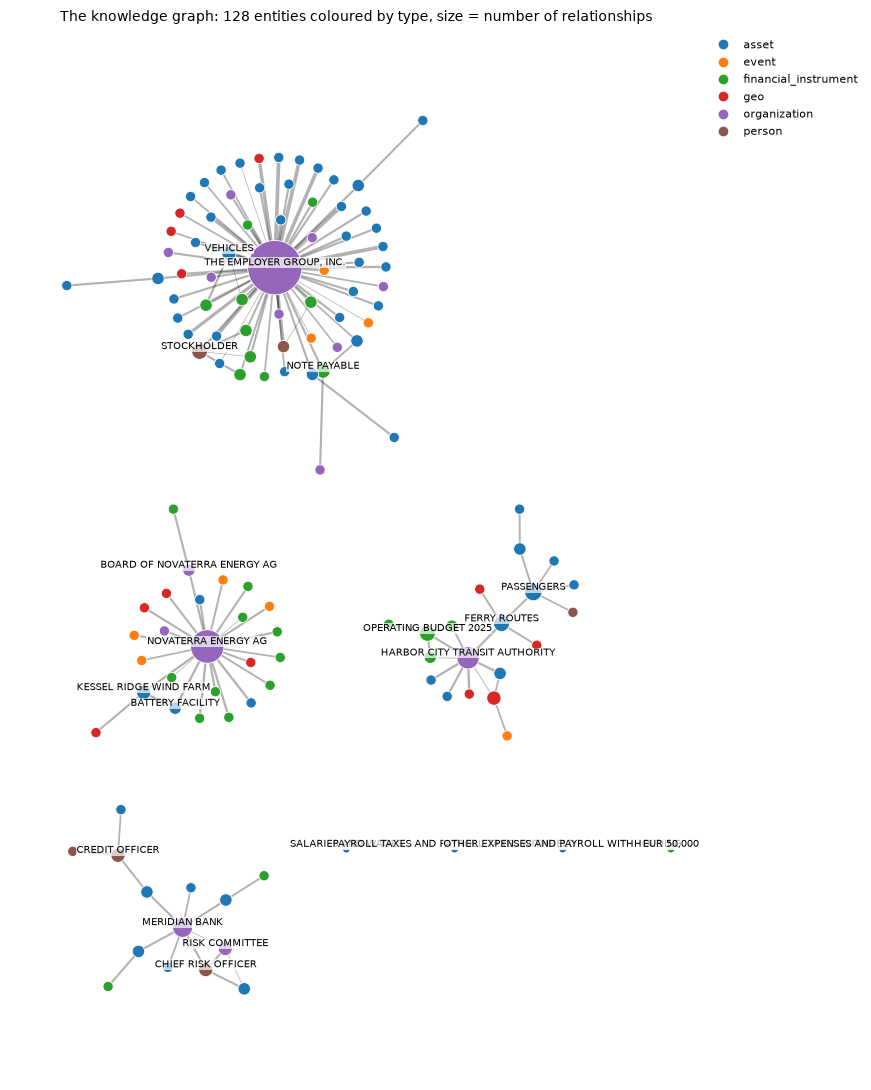

In [12]:
def packed_layout(graph, row_width=3.5, gap=0.15):
    parts = sorted(nx.connected_components(graph), key=len, reverse=True)
    positions, x, y, row_height = {}, 0.0, 0.0, 0.0
    for nodes in parts:
        sub = graph.subgraph(nodes)
        local = nx.kamada_kawai_layout(sub, weight=None) if len(nodes) > 2 else nx.circular_layout(sub)
        points = np.array([local[node] for node in sub.nodes])
        points = points - points.mean(axis=0)
        points = points / (np.abs(points).max() or 1)
        radius = np.sqrt(len(nodes) / len(parts[0])) + 0.08
        if x > 0 and x + 2 * radius > row_width:
            x, y, row_height = 0.0, y - row_height - gap, 0.0
        center = np.array([x + radius, y - radius])
        for node, point in zip(sub.nodes, points):
            positions[node] = center + point * radius
        x += 2 * radius + gap
        row_height = max(row_height, 2 * radius)
    return positions


def draw_graph(graph, positions, color_of, legend, title, labels_per_component=4, figsize=(16, 11)):
    fig, ax = plt.subplots(figsize=figsize)
    ax.set_aspect("equal")
    nx.draw_networkx_edges(graph, positions, ax=ax, alpha=0.3,
                           width=[0.4 + min(graph.edges[e]["weight"], 20) / 8 for e in graph.edges])
    nx.draw_networkx_nodes(graph, positions, ax=ax, node_color=[color_of(n) for n in graph.nodes],
                           node_size=[30 + 25 * graph.degree(n) for n in graph.nodes],
                           edgecolors="white", linewidths=0.6)
    for nodes in nx.connected_components(graph):
        for node in sorted(nodes, key=graph.degree, reverse=True)[:labels_per_component]:
            ax.text(*positions[node], node, fontsize=7, ha="center", va="bottom",
                    bbox={"facecolor": "white", "alpha": 0.7, "edgecolor": "none", "pad": 0.4})
    ax.legend(handles=[plt.Line2D([], [], marker="o", ls="", color=color, label=label) for label, color in legend],
              fontsize=8, loc="upper left", bbox_to_anchor=(1.0, 1.0), frameon=False)
    ax.set_title(title)
    ax.set_axis_off()
    fig.tight_layout()
    plt.show()


positions = packed_layout(graph)
types = sorted({graph.nodes[n]["type"] for n in graph.nodes})
type_colors = {t: plt.get_cmap("tab10")(i) for i, t in enumerate(types)}
draw_graph(graph, positions, lambda n: type_colors[graph.nodes[n]["type"]],
           [(t, type_colors[t]) for t in types],
           f"The knowledge graph: {graph.number_of_nodes()} entities coloured by type, size = number of relationships")

What the picture shows:

- **One hub per document.** The Employer Group, Inc. has 74 relationships: its six chunks of statements and notes produce assets, liabilities, financial instruments and people, almost all tied directly to the company. Novaterra Energy AG, the Harbor City Transit Authority and Meridian Bank are the other hubs. The title in front of every chunk made "the Company" resolve to one entity. In a test run without it, the same model produced three nodes for the company – THE COMPANY, EMPLOYER GROUP, INC. and THE EMPLOYER GROUP, INC. – the "the company" problem of Examples 2 and 4 in graph form.
- **Entities are merged by name, nothing else.** Three of the four documents ended up in one connected component. The links are generic entities that several documents mention: NET INCOME connects Novaterra with the Employer Group, EUR connects Meridian's loan applicants with Novaterra's accounts, SHAREHOLDERS connects Novaterra with the Employer Group. Only the transit review stayed separate.
- **The type list is a request, not a constraint.** Besides the six types we asked for, the LLM also used LIABILITY.
- **One entity comes from the prompt, not from the documents.** ALHAMIA PRISON is a place in one of the worked examples inside GraphRAG's extraction prompt, and its description reads "Not present in this text, no extraction" – the model copied it from the example. Prompt tuning, which replaces the examples with ones from your own domain, reduces this.

### The communities

GraphRAG partitions the graph with the **Leiden** algorithm (Traag, Waltman & van Eck, 2019). Leiden looks for groups of nodes that are more densely connected among themselves than to the rest of the graph – it maximises *modularity* – and, unlike its predecessor Louvain, guarantees that every community is internally connected. GraphRAG applies it hierarchically: the communities of level 0 are the coarsest; every community with more than `max_cluster_size` entities is partitioned again, which gives level 1, and so on.

`communities` lists for every community its level, its parent and children, and its entities. We colour the graph by level-0 community, and name each one by the title the LLM gave its report.

24 communities on 3 levels: {0: 10, 1: 12, 2: 2} (level: count)
entities without a community: 4


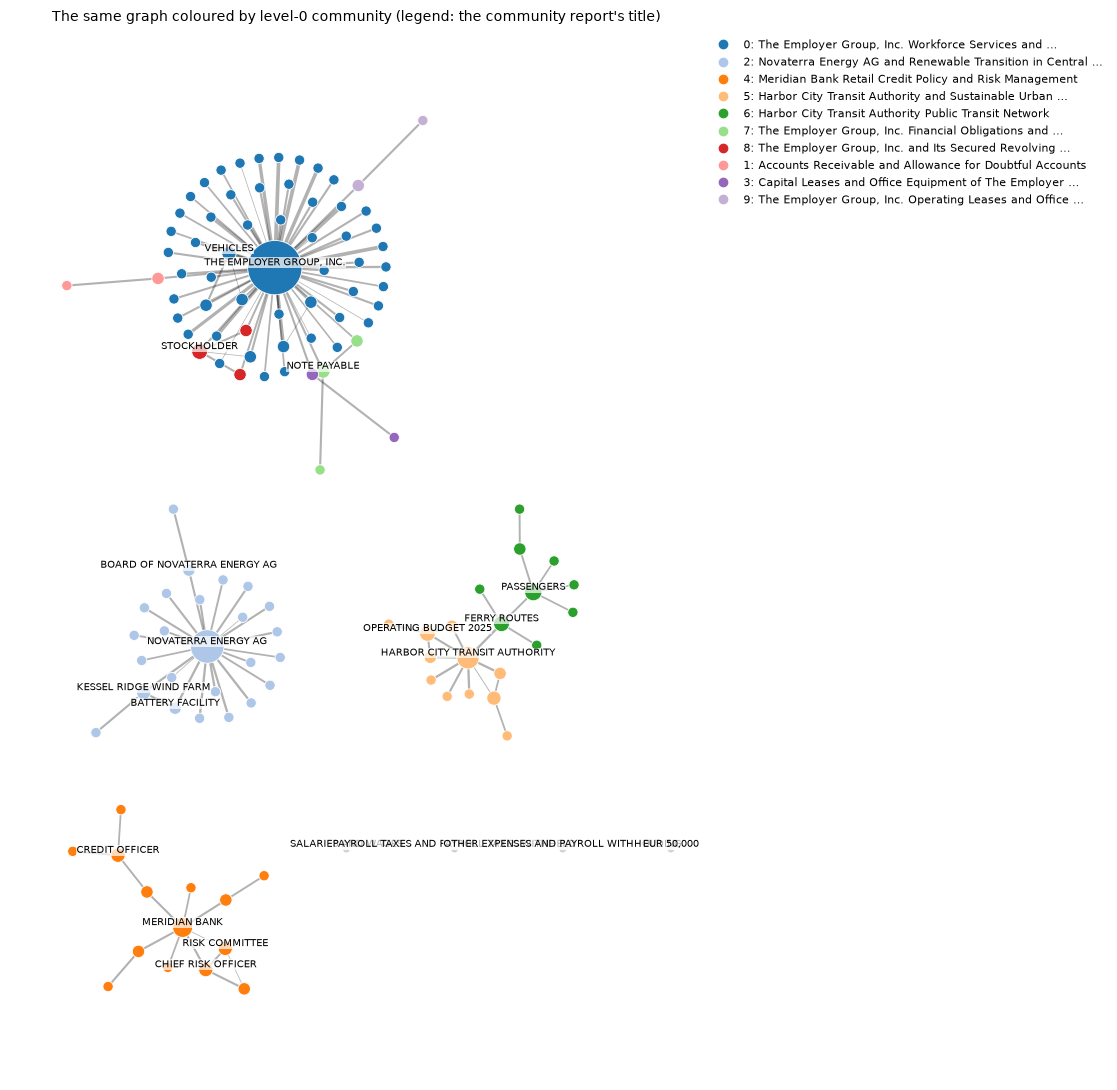

In [13]:
id_to_title = dict(zip(entities.id, entities.title))
report_titles = dict(zip(reports.community, reports.title))
top_level = communities[communities.level == 0].sort_values("size", ascending=False)
community_of = {id_to_title[entity_id]: row.community for row in top_level.itertuples() for entity_id in row.entity_ids}
palette = plt.get_cmap("tab20").colors
community_colors = {c: palette[i % 20] for i, c in enumerate(top_level.community)}

print(f"{len(communities)} communities on {communities.level.nunique()} levels: "
      f"{communities.groupby('level').size().to_dict()} (level: count)")
print(f"entities without a community: {len(set(graph.nodes) - set(community_of))}")
draw_graph(graph, positions, lambda n: community_colors.get(community_of.get(n), "lightgray"),
           [(f"{c}: {shorten(report_titles.get(c, ''), 58, placeholder=' …')}", community_colors[c])
            for c in top_level.community],
           "The same graph coloured by level-0 community (legend: the community report's title)")

Leiden found nine communities at level 0, and every entity except the two isolated ones belongs to one. They follow the documents and, inside the large Employer Group sub-graph, its topics: workforce management, accounts receivable, the financial structure and equity, the asset structure, capital leases, the revolving credit loans. Meridian Bank and the Harbor City Transit Authority each have a community of their own. Community 3, however, is titled "Novaterra Energy AG and The Employer Group, Inc. Financial and Operational Overview": the generic financial entities that link the two companies were enough for Leiden to put them together. Community detection follows the graph, and the graph follows the names.

### The community hierarchy

The tree below is drawn like a folder tree: one row per community, the level as the column, every sub-community indented under its parent, and each circle sized by the community's number of entities. `visit` walks the tree depth-first – largest communities first – and records the row order and the level-0 community each one belongs to, which gives the colour.

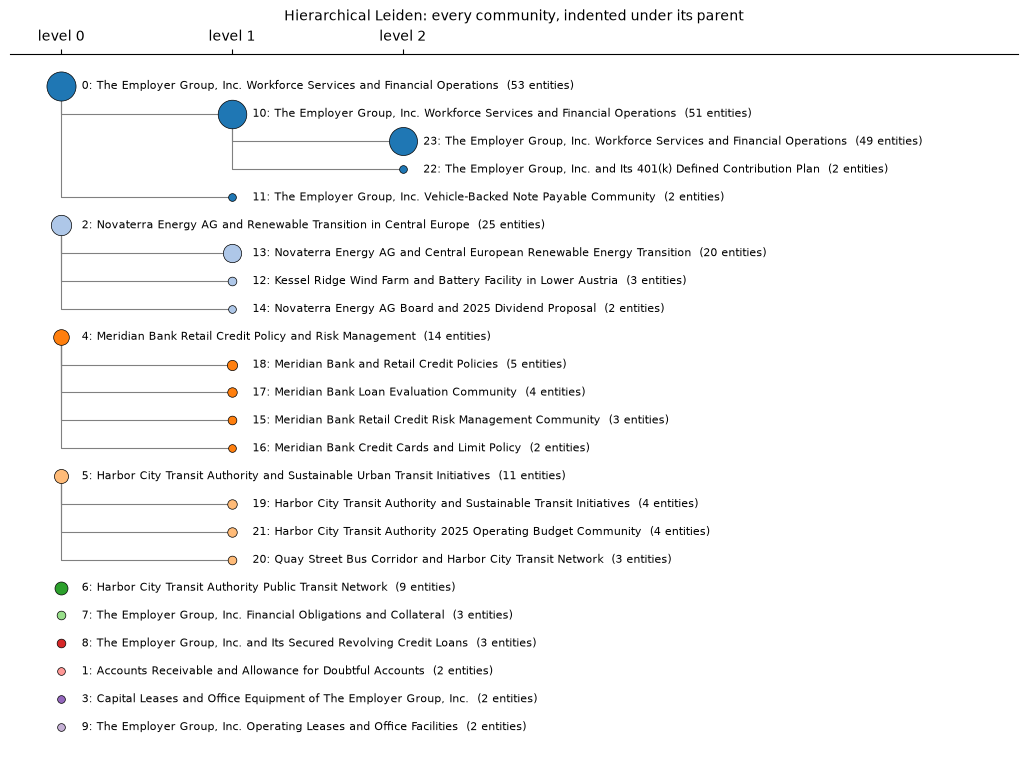

In [14]:
children = {row.community: list(row.children) for row in communities.itertuples()}
levels = dict(zip(communities.community, communities.level))
sizes = dict(zip(communities.community, communities["size"]))
order, root_of = [], {}


def visit(community, root):
    order.append(community)
    root_of[community] = root
    for kid in sorted(children[community], key=lambda k: -sizes[k]):
        visit(kid, root)


for root in top_level.community:
    visit(root, root)
row_of = {community: -i for i, community in enumerate(order)}

fig, ax = plt.subplots(figsize=(13, 0.34 * len(order) + 1))
for community in order:
    for kid in children[community]:
        ax.plot([levels[community], levels[community], levels[kid]], [row_of[community], row_of[kid], row_of[kid]],
                color="gray", lw=0.8, zorder=0)
for community in order:
    x, y = levels[community], row_of[community]
    ax.scatter(x, y, s=15 + 8 * sizes[community], color=community_colors[root_of[community]],
               edgecolor="black", linewidth=0.5, zorder=2)
    ax.text(x + 0.12, y, f"{community}: {report_titles.get(community, '')}  ({sizes[community]} entities)",
            va="center", fontsize=8)
ax.set_xticks(range(communities.level.max() + 1))
ax.set_xticklabels([f"level {level}" for level in range(communities.level.max() + 1)])
ax.xaxis.tick_top()
ax.set_xlim(-0.3, communities.level.max() + 3.6)
ax.set_yticks([])
for side in ["right", "bottom", "left"]:
    ax.spines[side].set_visible(False)
ax.set_title("Hierarchical Leiden: every community, indented under its parent", pad=24)
plt.show()

The four level-0 communities with more than ten entities were split again. Novaterra's became its location (Linz, Austria), its wind farm and battery facility, its board and dividend, and the shared financial overview. Meridian Bank's became loan applications, risk management and loan review. Harbor City's became the bus network and Quay Street, the network as a whole, the operating budget, and the ferry routes. Global search can read the reports of any level: level 0 gives few, broad reports, the deeper levels more and narrower ones.

A split does not always produce balanced parts. The Employer Group's 63 entities became 2 + 61, then 2 + 59, and the 59 were not split further despite `max_cluster_size: 10`. A star-shaped sub-graph, with almost everything attached to the company itself, gives Leiden nothing to cut.

### Zooming in: one community up close

The overview has to leave most names out. Here is one community in full, with every entity named and every edge labelled with its weight: the level-0 community that contains Meridian Bank. Below the picture, the relationships with their descriptions – this is what GraphRAG's LLM wrote about each connection.

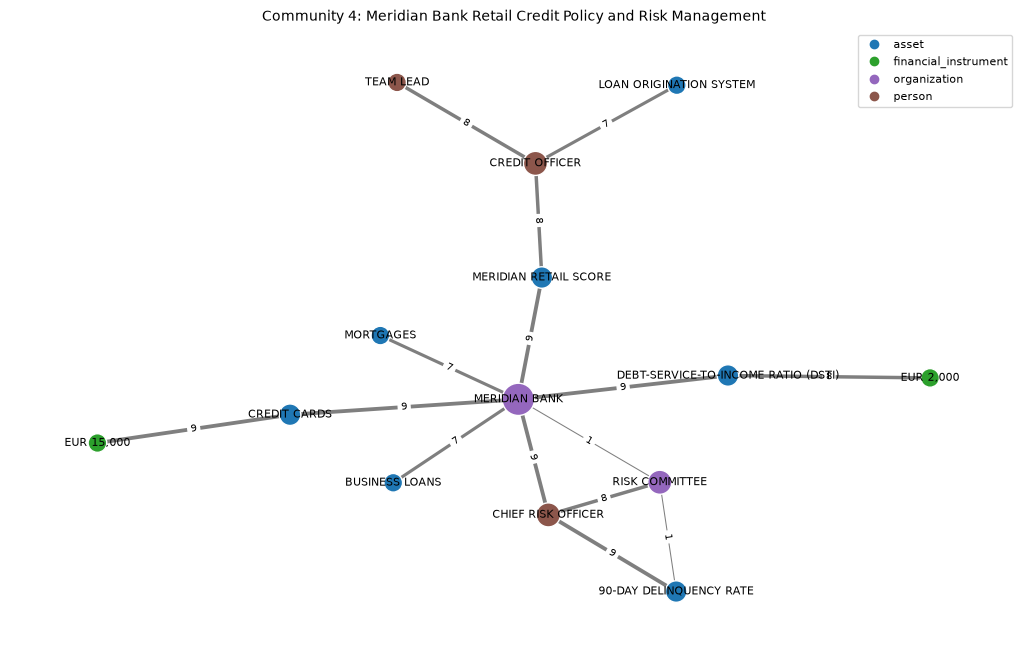

CHIEF RISK OFFICER - MERIDIAN BANK (9): The Chief Risk Officer owns the Retail Credit Policy and manages risk-related activities at Meridian Bank
RISK COMMITTEE - CHIEF RISK OFFICER (8): The Chief Risk Officer presents remediation plans to the Risk Committee when delinquency rates exceed thresholds
MERIDIAN RETAIL SCORE - CREDIT OFFICER (8): The Meridian Retail Score is used by credit officers to evaluate loan applications and determine if manual review is needed
CREDIT OFFICER - TEAM LEAD (8): Credit officers require written approval from a team lead to override automatic declines on loan applications
LOAN ORIGINATION SYSTEM - CREDIT OFFICER (7): Credit officers document override reasons in the loan origination system
MERIDIAN BANK - MERIDIAN RETAIL SCORE (9): Meridian Bank uses the Meridian Retail Score as its internal credit scoring system for retail loan applications
MERIDIAN BANK - RISK COMMITTEE (1): The Risk Committee is part of Meridian Bank's governance structure overseeing ri

In [15]:
focus = community_of["MERIDIAN BANK"]
members = [n for n, c in community_of.items() if c == focus]
sub = graph.subgraph(members)
sub_positions = nx.kamada_kawai_layout(sub, weight=None)

fig, ax = plt.subplots(figsize=(13, 8))
nx.draw_networkx_edges(sub, sub_positions, ax=ax, alpha=0.5, width=[0.5 + sub.edges[e]["weight"] / 4 for e in sub.edges])
nx.draw_networkx_nodes(sub, sub_positions, ax=ax, node_color=[type_colors[sub.nodes[n]["type"]] for n in sub.nodes],
                       node_size=[120 + 60 * sub.degree(n) for n in sub.nodes], edgecolors="white")
nx.draw_networkx_labels(sub, sub_positions, labels={n: n for n in sub.nodes}, font_size=8, ax=ax)
nx.draw_networkx_edge_labels(sub, sub_positions, edge_labels={e: f"{sub.edges[e]['weight']:g}" for e in sub.edges},
                             font_size=7, ax=ax)
present = sorted({sub.nodes[n]["type"] for n in sub.nodes})
ax.legend(handles=[plt.Line2D([], [], marker="o", ls="", color=type_colors[t], label=t) for t in present], fontsize=8)
ax.set_title(f"Community {focus}: {report_titles.get(focus, '')}")
ax.set_axis_off()
plt.show()

for row in relationships[relationships.source.isin(members) & relationships.target.isin(members)].itertuples():
    print(f"{row.source} - {row.target} ({row.weight:g}): {row.description}")

### An interactive view

A static drawing of a whole knowledge graph can only show so much. `pyvis` writes an interactive page (based on the vis-network JavaScript library): drag nodes, zoom with the mouse wheel – the names appear as you zoom in – and hover over a node or an edge to read its description. The layout settles for a few seconds after loading. Nodes are coloured by level-0 community, sized by the square root of their degree (so the hub does not swallow the picture), and edges are as thick as their weight. `cdn_resources="in_line"` embeds the JavaScript into the page, so it works offline. The page is saved as `graphrag_workspace/knowledge_graph.html`, which you can also open in a browser, and shown below in an `iframe`.

In [16]:
def hex_color(rgb):
    return "#" + "".join(f"{int(255 * v):02x}" for v in rgb[:3])


network = Network(height="700px", width="100%", cdn_resources="in_line", bgcolor="#ffffff")
for node in graph.nodes:
    color = community_colors.get(community_of.get(node), (0.8, 0.8, 0.8))
    network.add_node(node, label=node, color=hex_color(color), size=6 + 5 * np.sqrt(graph.degree(node)),
                     title=f"{node} ({graph.nodes[node]['type']})\n\n{graph.nodes[node]['description']}")
for source, target, data in graph.edges(data=True):
    network.add_edge(source, target, title=f"{data['description']} (weight {data['weight']:g})",
                     width=0.5 + min(data["weight"], 20) / 4)
network.barnes_hut(gravity=-5000, spring_length=110)

page = network.generate_html()
(WORKSPACE / "knowledge_graph.html").write_text(page, encoding="utf-8")
display(HTML(f'<div><iframe srcdoc="{escape(page)}" width="100%" height="720" style="border: 1px solid #ddd"></iframe></div>'))

## Step 6 – Community reports

For every community, an LLM wrote a report from the community's entities, relationships and (where they fit into 8,000 tokens) source texts. A report has a title, a summary, an importance rating (`rank`, 0–10) with an explanation, and a list of *findings*, each with a short summary and an explanation. Global search reads these reports – not the original text. Here is the report of the community we zoomed into:

In [17]:
report = reports[reports.community == focus].iloc[0]
lines = [f"### {report.title}", f"*level {report.level}, {report['size']} entities, rank {report['rank']}*",
         report.summary, "**Findings**"]
lines += [f"- **{finding['summary']}** {finding['explanation']}" for finding in report.findings]
display(Markdown("\n\n".join(lines)))

### Meridian Bank Retail Credit Policy and Risk Management

*level 0, 14 entities, rank 6.5*

This community centers around Meridian Bank and its Retail Credit Policy, which governs the issuance of unsecured personal loans and credit cards to private individuals. Key entities include the Chief Risk Officer, who owns and manages the Retail Credit Policy and oversees risk-related activities, the Risk Committee that receives remediation plans, and the credit officers who evaluate loan applications using the Meridian Retail Score and Debt-Service-to-Income Ratio (DSTI) metrics. The community also involves operational systems such as the Loan Origination System and supervisory roles like the Team Lead who approves overrides. The relationships among these entities reflect a structured risk management and credit evaluation process aimed at maintaining loan portfolio quality and compliance with internal thresholds.

**Findings**

- **Meridian Bank's Retail Credit Policy governs unsecured personal loans and credit cards** Meridian Bank issues unsecured personal loans and credit cards to private individuals under its Retail Credit Policy Version 7.2. This policy defines the terms and conditions for these retail credit products, excluding mortgages and business loans which are covered by separate policies. The policy's scope and application are central to the bank's retail lending operations and risk management framework [Data: Entities (88, 95, 96, 97)].

- **Chief Risk Officer owns the Retail Credit Policy and manages risk oversight** The Chief Risk Officer (CRO) at Meridian Bank is responsible for owning the Retail Credit Policy, reviewing it annually, and presenting remediation plans to the Risk Committee if delinquency rates exceed defined thresholds. This role is pivotal in ensuring that credit risk is monitored and mitigated effectively, maintaining the health of the bank's retail loan portfolio [Data: Entities (89, 91); Relationships (93, 94, 106)].

- **Meridian Retail Score is the internal credit scoring system for loan evaluation** Meridian Bank utilizes the Meridian Retail Score, an internal credit scoring system ranging from 0 to 1,000, to evaluate loan applications. This score determines whether applications are automatically declined, sent for manual review, or approved. Credit officers rely on this score to make informed decisions, with borderline cases requiring further scrutiny [Data: Entities (90, 94); Relationships (98, 95)].

- **Debt-Service-to-Income Ratio (DSTI) is a key metric for assessing loan affordability** The DSTI ratio is used by Meridian Bank to assess an applicant's ability to repay loans, with limits set at 40% or 30% depending on income levels. A monthly net income threshold of EUR 2,000 determines the applicable DSTI limits. This metric helps ensure that borrowers do not overextend financially, reducing the risk of delinquency [Data: Entities (98, 101); Relationships (103, 105)].

- **Credit officers perform manual reviews and require team lead approval for overrides** Credit officers are responsible for reviewing loan applications, including those with borderline Meridian Retail Scores. They can override automatic declines but must obtain written approval from a team lead. All override reasons are documented in the Loan Origination System, ensuring accountability and traceability in credit decisions [Data: Entities (94, 93, 92); Relationships (96, 97)].

- **90-day delinquency rate is monitored to trigger remediation actions** Meridian Bank monitors the 90-day delinquency rate on retail loans monthly. If this rate exceeds 3% for two consecutive months, the Chief Risk Officer must present remediation plans to the Risk Committee. This process is critical for early detection of credit quality deterioration and timely intervention [Data: Entities (102, 89, 91); Relationships (106, 94)].

- **Credit card limits are capped at EUR 15,000 under the Retail Credit Policy** The Retail Credit Policy sets an absolute cap of EUR 15,000 on credit card limits issued by Meridian Bank. This limit helps control credit exposure and manage risk associated with unsecured credit products [Data: Entities (95); Relationships (104)].

## Step 7 – Asking questions

All search functions take the configuration, the tables they need and the question, and return the answer together with the *context* they gave the LLM. `RESPONSE_TYPE` asks for "multiple paragraphs"; answers are Markdown, so we display them formatted. Each search takes a few seconds.

### Global search: a question about the whole corpus

Global search runs a map–reduce over the community reports up to `COMMUNITY_LEVEL`. In the *map* step the LLM reads the reports in batches and writes intermediate answers with importance scores. In the *reduce* step it combines the most important points into the final answer. No vector search is involved: every report is read, so the answer can cover the whole corpus. That is the point of GraphRAG, and the kind of question that plain vector RAG cannot answer well.

In [18]:
question = "What are the main topics of these documents, and which organisations do they describe?"
start = time.time()
answer, context = await api.global_search(
    config=config, entities=entities, communities=communities, community_reports=reports,
    community_level=COMMUNITY_LEVEL, dynamic_community_selection=False,
    response_type=RESPONSE_TYPE, query=question,
)
print(f"global search: {time.time() - start:.0f} s, {len(context['reports'])} community reports in the context\n")
display(Markdown(answer))

global search: 9 s, 24 community reports in the context



The documents primarily focus on four main organizations, each representing distinct sectors and operational themes. The key topics revolve around workforce management and financial operations, retail credit policy and risk management, renewable energy transition and asset management, and sustainable urban transit initiatives. Below is a detailed synthesis of the main topics and the organizations described.

### The Employer Group, Inc.

A significant portion of the documents centers on The Employer Group, Inc., a professional employer organization (PEO) that manages workforce-related administrative and compliance functions for small businesses, primarily in the Mid-Western and Western United States. The organization handles a complex array of workforce services including employee benefits administration, notably a 401(k) retirement plan, and manages financial operations involving operating and capital leases, secured notes payable, and equity components. It operates under a Subchapter S corporation tax status, which influences its financial and tax reporting structures. The documents detail its financial statements, asset and liability management, and employee retirement plans, highlighting the organization's comprehensive approach to workforce services and financial structuring [Data: Reports (0, 7, 8, 23, +more)].

### Meridian Bank

Meridian Bank is described with a focus on its retail credit policy governing unsecured personal loans and credit cards. The bank employs an internal credit scoring system known as the Meridian Retail Score to assess creditworthiness. It maintains structured risk management and oversight processes involving the Chief Risk Officer and a Risk Committee. Key operational aspects include monitoring delinquency rates, setting credit card limits, and applying loan affordability metrics such as the Debt-Service-to-Income Ratio and income thresholds to guide loan approvals. The documents also describe the roles of Credit Officers and Team Leads in manual review and override processes, as well as documentation practices within the Loan Origination System. These elements collectively illustrate Meridian Bank’s comprehensive framework for credit risk assessment and retail lending operations [Data: Reports (4, 15, 16, +more)].

### Novaterra Energy AG

Novaterra Energy AG is a major utility headquartered in Linz, Austria, undergoing a strategic transition from coal-fired power generation to renewable energy sources, particularly wind power and battery storage assets. The company serves the Central European market and reports strong financial performance in 2025. Key renewable assets include the Kessel Ridge wind farm and a grid-scale battery facility. The Board of Directors governs corporate decisions, including dividend proposals and capital expenditure plans aimed at expanding wind capacity and upgrading the electrical grid. These initiatives reflect Novaterra’s commitment to sustainable energy and its strategic investment in renewable infrastructure to support the energy transition in Central Europe [Data: Reports (12, 13, 14, +more)].

### Harbor City Transit Authority

The Harbor City Transit Authority operates the public transportation network in Harbor City, encompassing buses, trams, and ferries. The documents highlight the Authority’s focus on sustainability initiatives such as converting the tram fleet to regenerative braking technology and planning dedicated bus lanes to improve service efficiency and reliability. Challenges related to traffic congestion, particularly along the Quay Street bus corridor, are addressed through infrastructure investments aimed at enhancing punctuality and transit efficiency. The Authority’s operating budget and funding sources are also discussed, underscoring the financial and operational planning involved in managing a large urban transit system [Data: Reports (5, 6, 19, 21, +more)].

---

### Summary

In summary, the documents collectively cover:

- Workforce services and financial operations of The Employer Group, Inc.
- Retail credit policy, risk management, and loan evaluation at Meridian Bank.
- Renewable energy transition, asset management, and strategic investments by Novaterra Energy AG.
- Sustainable urban transit infrastructure and operational improvements by the Harbor City Transit Authority.

These topics encompass financial structures, operational strategies, risk management frameworks, and infrastructure investments within their respective organizations, providing a comprehensive view of their sector-specific challenges and initiatives [Data: Reports (0, 4, 5, 6, 7, 12, 13, 14, 15, 16, 19, 21, 23, +more)].

The answer covers all four organisations, and every paragraph cites the community reports it is based on. This is the kind of answer plain vector RAG cannot give. No chunk contains it, and a top-*k* retrieval returns the *k* chunks most similar to the question – which say nothing about the corpus as a whole. Notebook 5's tree can answer such questions from its upper nodes too; GraphRAG organises its summaries around entities and their connections instead of embedding clusters.

Without `use_lcc: false` this answer would mention only the documents in the largest connected component (*Things to try*, 7).

### Local search: a question about specific entities

Local search starts from the question's entities. It embeds the question, finds the entities whose descriptions are most similar (in the LanceDB table of entity descriptions), and builds a context from them: their descriptions, their relationships, the text units they come from, and the reports of their communities, all within a token budget. Then one LLM call answers. The question below is about one bank's rules; its answer sits in one place in the corpus.

In [19]:
question = "Who has to approve an override of an automatically declined loan at Meridian Bank?"
start = time.time()
answer, context = await api.local_search(
    config=config, entities=entities, communities=communities, community_reports=reports,
    text_units=text_units, relationships=relationships, covariates=None,
    community_level=COMMUNITY_LEVEL, response_type=RESPONSE_TYPE, query=question,
)
print(f"local search: {time.time() - start:.0f} s; context: "
      + ", ".join(f"{len(table)} {name}" for name, table in context.items()) + "\n")
display(Markdown(answer))

local search: 3 s; context: 2 reports, 23 relationships, 0 claims, 19 entities, 4 sources



# Override Approval Process at Meridian Bank

At Meridian Bank, when a loan application is automatically declined based on the internal credit scoring system (Meridian Retail Score), an override of this decision can only be performed under strict supervision. Specifically, a **credit officer** may override an automatic decline, but this action requires **written approval from a team lead**. This ensures that overrides are carefully controlled and subject to supervisory review.

# Documentation and Limits on Overrides

Furthermore, every override must be documented with a reason code in the Loan Origination System, providing accountability and traceability for these exceptions. Additionally, overrides are limited to no more than 5 percent of all approved applications in any calendar quarter, reflecting the bank's cautious approach to managing credit risk through overrides.

# Summary

- Overrides of automatic declines are initiated by credit officers.
- Written approval from a team lead is mandatory before an override can be applied.
- All overrides must be documented in the Loan Origination System.
- Overrides are capped at 5 percent of approved applications per quarter.

This structured process helps Meridian Bank maintain rigorous credit risk management while allowing some flexibility for borderline cases [Data: Reports (4, 18); Entities (93, 94, 92); Relationships (96, 97, 95)].

The context is returned as tables, so we can see exactly what the LLM was given. Here are the entities local search selected (red), together with the entities they are connected to (grey), laid out with `packed_layout` from above:

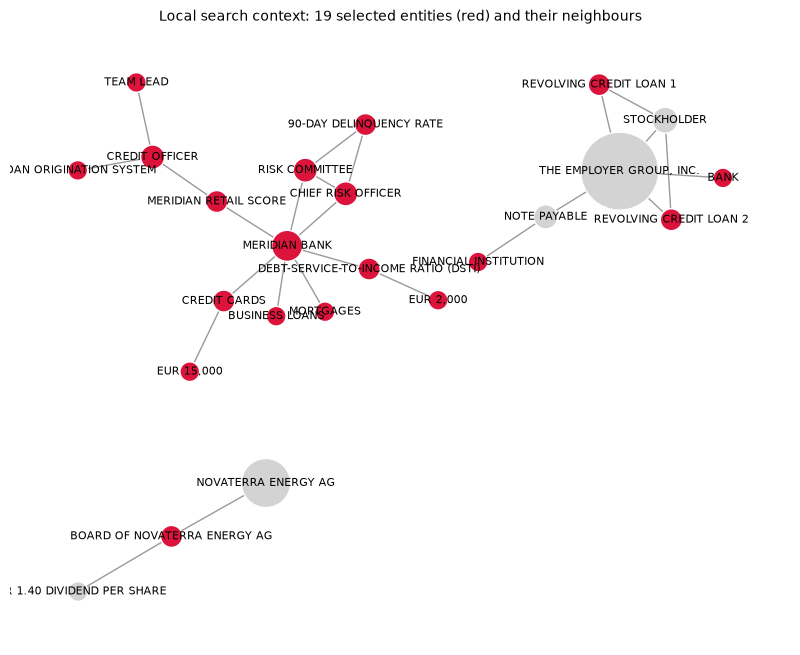

,entity,description
0,TEAM LEAD,A supervisory role at Meridian Bank authorized...
1,LOAN ORIGINATION SYSTEM,The system used by Meridian Bank to document l...
2,RISK COMMITTEE,The committee at Meridian Bank that receives r...
3,MERIDIAN RETAIL SCORE,The internal credit scoring system used by Mer...
4,CREDIT OFFICER,Bank personnel responsible for reviewing loan ...
5,MERIDIAN BANK,Meridian Bank is a fictional bank created for ...
6,CHIEF RISK OFFICER,The Chief Risk Officer owns the Retail Credit ...
7,MORTGAGES,Loans for property purchase covered by separat...
8,CREDIT CARDS,Credit cards issued by Meridian Bank to privat...
9,90-DAY DELINQUENCY RATE,A performance metric monitored monthly by Meri...


In [20]:
selected = set(context["entities"]["entity"])
neighbourhood = graph.subgraph(set().union(*(set(graph.neighbors(n)) | {n} for n in selected if n in graph)))
local_positions = packed_layout(neighbourhood, row_width=4.5)

fig, ax = plt.subplots(figsize=(15, 8))
ax.set_aspect("equal")
nx.draw_networkx_edges(neighbourhood, local_positions, ax=ax, alpha=0.4)
nx.draw_networkx_nodes(neighbourhood, local_positions, ax=ax,
                       node_color=["crimson" if n in selected else "lightgray" for n in neighbourhood.nodes],
                       node_size=[150 + 50 * graph.degree(n) for n in neighbourhood.nodes], edgecolors="white")
nx.draw_networkx_labels(neighbourhood, local_positions, labels={n: n for n in neighbourhood.nodes}, font_size=8, ax=ax)
ax.set_title(f"Local search context: {len(selected)} selected entities (red) and their neighbours")
ax.set_axis_off()
plt.show()
context["entities"][["entity", "description"]]

The answer is right, and it cites entities, relationships and a community report. The picture shows how local search assembled its context. Around Meridian Bank's own entities – credit officer, team lead, loan origination system, risk committee, retail score – it also picked up entities that are merely *similar* to the question: the Employer Group's revolving credit loans and note payable, Novaterra's board. The selection is a vector search over entity descriptions, so anything about loans and approvals competes. The token budget and the LLM's reading do the rest.

Compare this with the community report in step 6. One of its findings says that team leads "have override limits capped at 5 percent of approved applications per quarter". The policy says that overrides may not exceed 5 percent of all approved applications in a quarter – nothing about team leads' limits. Reports are summaries of summaries, and details can drift. Local search also reads the original text units and gets it right.

### Basic search: the vector-RAG baseline

Basic search ignores the graph: it embeds the question, retrieves the most similar text units from LanceDB and answers from them, like Example 1. The same question as above:

In [21]:
start = time.time()
answer, context = await api.basic_search(config=config, text_units=text_units, response_type=RESPONSE_TYPE, query=question)
print(f"basic search: {time.time() - start:.0f} s, {len(context['sources'])} text units in the context\n")
display(Markdown(answer))

basic search: 2 s, 9 text units in the context



### Override Approval at Meridian Bank

At Meridian Bank, an override of an automatically declined unsecured personal loan or credit card application requires written approval from a team lead. This means that if an application initially scores below the automatic decline threshold but is considered for approval upon further review, the credit officer must obtain explicit written consent from a team lead before proceeding.

### Additional Details on Overrides

- Overrides are limited in frequency and may not exceed 5 percent of all approved applications in any calendar quarter.
- Every override must be documented with a reason code in the loan origination system to ensure proper tracking and accountability.

This policy ensures that overrides are carefully controlled and monitored to maintain credit quality and risk management standards at the bank [Data: Sources (7)].

Basic search answers this question just as well, from a single text unit: the answer sits in one place in one document, which is exactly the case vector RAG handles well. GraphRAG's local search pays off for questions that need connected facts from several chunks or documents, and its global search for questions about the corpus as a whole. *Things to try* (10) runs the global question through basic search.

## What GraphRAG adds – and what it costs

- **What it adds.** An explicit, inspectable model of the corpus – entities, relationships, communities – and summaries organised by that structure. Global search turns the summaries into answers about the whole corpus; local search answers from an entity's neighbourhood across all documents.
- **What it costs.** Indexing our four short documents took under a minute and a half and 78 model calls: 18 for extraction, 23 description merges, 24 community reports and 13 embedding batches. Notebook 5's RAPTOR tree needed 12 LLM calls, Example 1's vector index none. The cost grows with the corpus – extraction is one call plus a gleaning pass per chunk, reports one call per community – and a change of the extraction prompt or the chunking means extracting everything again.
- **What to watch.** The graph is only as good as the extraction. Entities are merged by exact name, so generic entities such as EUR or NET INCOME join unrelated documents, while a missing title split one company into three nodes. The LLM may invent types or copy entities from the prompt's examples. And reports, as summaries of summaries, can drift from the source. Two defaults need care: clustering only the largest connected component (`use_lcc`), and an entity-type list that may not fit your domain.
- **When to use it.** For corpora with many interconnected entities – people, organisations, places, events – and questions about themes, relationships or the corpus as a whole. For looking up single facts, plain vector RAG, ideally with a reranker (Example 3), is cheaper and usually just as good.

## Things to try

1. **Prompt tuning.** `graphrag prompt-tune --root graphrag_workspace --domain "financial statements and corporate reports"` (from a terminal with the project's `venv` activated) asks the LLM to write extraction and report prompts adapted to the documents, including entity types. Point `extract_graph.prompt` at the generated file, delete `output/` and rebuild. Does the graph change?
2. **Smaller chunks.** The paper reports that 600-token chunks extract almost twice as many entity references as 2,400-token ones. Set `"size": 600` and rebuild. How many entities and communities do you get, and how much longer does indexing take?
3. **Default entity types.** Remove `asset` and `financial_instrument` from `ENTITY_TYPES` and rebuild. Which entities disappear or change type?
4. **DRIFT search.** `await api.drift_search(config=config, entities=entities, communities=communities, community_reports=reports, text_units=text_units, relationships=relationships, community_level=COMMUNITY_LEVEL, response_type=RESPONSE_TYPE, query=...)` combines a global primer with local follow-up questions. It makes many more LLM calls; compare its answer to the global one.
5. **Dynamic community selection.** Run the global search with `dynamic_community_selection=True`: the LLM first rates which reports are relevant and only reads those. Is the answer as complete?
6. **Look at the graph elsewhere.** Open `graphrag_workspace/output/graph.graphml` in [Gephi](https://gephi.org/), or `graphrag_workspace/knowledge_graph.html` in a browser.
7. **Restore the default.** Set `"use_lcc": True`, delete `output/` and rebuild (the extraction is cached, so only the communities, reports and embeddings are new). Ask the global question again – which documents disappear from the answer? And what does local search answer about Meridian Bank now?
8. **Run it locally with Ollama**, like the rest of the project. For the completion model use `model_provider: ollama_chat`, `model: mistral-small3.2:24b`, `api_base: http://localhost:11434` and any non-empty `api_key` (Ollama ignores it, GraphRAG requires one); add `"timeout": 1800` to `call_args`; and set `concurrent_requests` to 4, because Ollama works through long requests largely one at a time. For the embeddings use `model_provider: ollama` with `model: embeddinggemma:300m`, and set `vector_size: 768`. Expect roughly 45 minutes of indexing on a laptop.
9. **Leave out the title.** Remove `"prepend_metadata": ["title"]` and rebuild. In our test run, the same model then created three separate nodes for one company: THE COMPANY (33 relationships), EMPLOYER GROUP, INC. (10) and THE EMPLOYER GROUP, INC. (6).
10. **The global question with basic search.** Ask the corpus-wide question of section 7 with `api.basic_search`. What does vector retrieval of a few chunks make of it?